In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [62]:
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from PIL import Image
from torch.utils.data import Dataset
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchinfo
import torchvision
from torchvision import models
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
from torch.utils.data import DataLoader
from torchinfo import summary
from torchvision import datasets, transforms
from tqdm import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [63]:
print("torch version : ", torch.__version__)
print("torchvision version : ", torchvision.__version__)
print("torchinfo version : ", torchinfo.__version__)
print("numpy version : ", np.__version__)
print("matplotlib version : ", matplotlib.__version__)

!python --version

torch version :  2.11.0+cu128
torchvision version :  0.26.0+cu128
torchinfo version :  1.8.0
numpy version :  2.1.3
matplotlib version :  3.10.0
Python 3.13.15


In [64]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using {device} device.")

Using cuda device.


In [65]:
import os

# Get the directory where the files live, rather than the file itself
for dirname, _, filenames in os.walk("/kaggle/input"):
    if filenames:  # Make sure it's not an empty folder
        data_path = dirname
        break

print("Directory path:", data_path)

Directory path: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset


In [66]:
print(data_path)

/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset


In [67]:
root = os.listdir(data_path)
print(root)

['COVID', 'COVID.metadata.xlsx', 'Lung_Opacity', 'Lung_Opacity.metadata.xlsx', 'Normal', 'Normal.metadata.xlsx', 'README.md.txt', 'Viral Pneumonia', 'Viral Pneumonia.metadata.xlsx']


In [68]:
for dirpath, dirnames, filenames in os.walk(data_path):
    depth = dirpath[len(data_path):].count(os.sep)
    if depth <= 3:
        print(f"{dirpath}  ->  {len(filenames)} files")

/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset  ->  5 files
/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/COVID  ->  0 files
/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/COVID/images  ->  3616 files
/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/COVID/masks  ->  3616 files
/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Lung_Opacity  ->  0 files
/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Lung_Opacity/images  ->  6012 files
/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Lung_Opacity/masks  ->  6012 files
/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal  ->  0 files
/kaggle/input/datasets/taw

In [69]:
data_dir = os.path.join(data_path)
print(os.listdir(data_dir))

['COVID', 'COVID.metadata.xlsx', 'Lung_Opacity', 'Lung_Opacity.metadata.xlsx', 'Normal', 'Normal.metadata.xlsx', 'README.md.txt', 'Viral Pneumonia', 'Viral Pneumonia.metadata.xlsx']


In [70]:
classes = os.listdir(data_dir)

In [71]:
classes = sorted(
    d for d in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, d))
)
print(classes)

['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']


In [72]:
# count files one folder deeper
for class_name in classes:
    for sub in ["images", "masks"]:
        sub_path = os.path.join(data_dir, class_name, sub)
        print(f"📁{class_name}/{sub}: {len(os.listdir(sub_path))} files")

📁COVID/images: 3616 files
📁COVID/masks: 3616 files
📁Lung_Opacity/images: 6012 files
📁Lung_Opacity/masks: 6012 files
📁Normal/images: 10192 files
📁Normal/masks: 10192 files
📁Viral Pneumonia/images: 1345 files
📁Viral Pneumonia/masks: 1345 files


In [73]:
from pathlib import Path
import pandas as pd

data_dir = Path(data_dir)

rows = []
for cls in data_dir.iterdir():
    if cls.is_dir():
        for p in (cls / "images").glob("*.png"):
            rows.append({"path": str(p), "label": cls.name})

df = pd.DataFrame(rows)
print(df.shape)
print(df["label"].value_counts())

(21165, 2)
label
Normal             10192
Lung_Opacity        6012
COVID               3616
Viral Pneumonia     1345
Name: count, dtype: int64


In [74]:
df.sample(8)
# print(df.describe())

,path,label
7774,/kaggle/input/datasets/tawsifurrahman/covid19-...,Lung_Opacity
18922,/kaggle/input/datasets/tawsifurrahman/covid19-...,Normal
17546,/kaggle/input/datasets/tawsifurrahman/covid19-...,Normal
3707,/kaggle/input/datasets/tawsifurrahman/covid19-...,Lung_Opacity
5044,/kaggle/input/datasets/tawsifurrahman/covid19-...,Lung_Opacity
4767,/kaggle/input/datasets/tawsifurrahman/covid19-...,Lung_Opacity
8206,/kaggle/input/datasets/tawsifurrahman/covid19-...,Lung_Opacity
755,/kaggle/input/datasets/tawsifurrahman/covid19-...,COVID


In [75]:
df.head()

,path,label
0,/kaggle/input/datasets/tawsifurrahman/covid19-...,COVID
1,/kaggle/input/datasets/tawsifurrahman/covid19-...,COVID
2,/kaggle/input/datasets/tawsifurrahman/covid19-...,COVID
3,/kaggle/input/datasets/tawsifurrahman/covid19-...,COVID
4,/kaggle/input/datasets/tawsifurrahman/covid19-...,COVID


In [76]:
# Open the first X-ray image in your dataframe
img = Image.open(df["path"].iloc[0])

# Print the image type and dimensions
print("Image mode:", img.mode)
print("Image size:", img.size)

Image mode: L
Image size: (299, 299)


label
Normal             10192
Lung_Opacity        6012
COVID               3616
Viral Pneumonia     1345
Name: count, dtype: int64


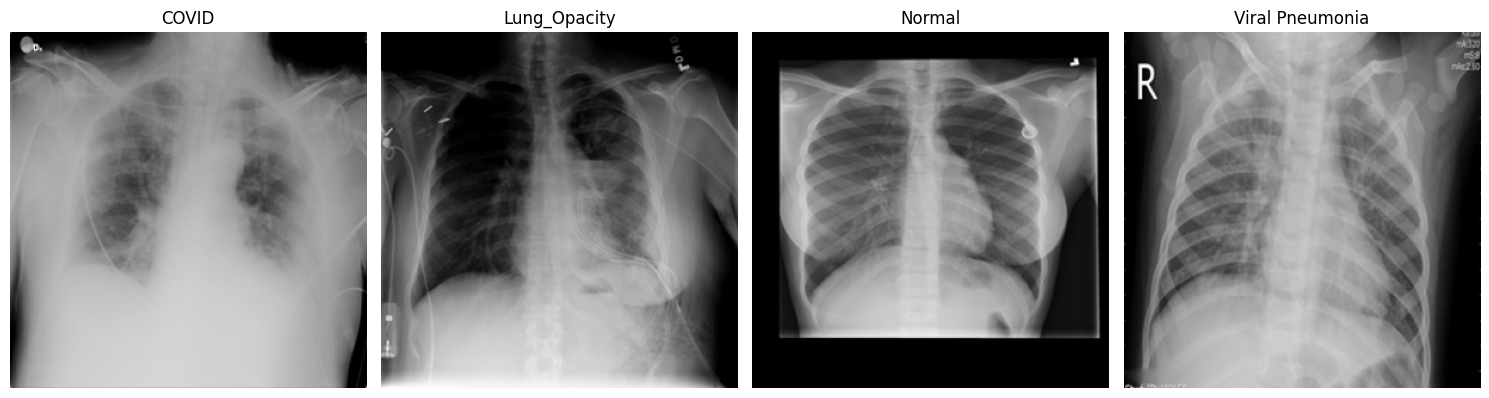

In [77]:
# print the value_counts
print(df['label'].value_counts())

# 2. Plot a sample image from each class
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
classes = df['label'].unique()

for idx, label in enumerate(classes):
    sample_path = df[df['label'] == label]['path'].iloc[0]
    img = Image.open(sample_path)
    axes[idx].imshow(img, cmap='gray')
    axes[idx].set_title(label)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

**SPLIT THE DATASET**

In [78]:
# Instantiate the label encoder
le = LabelEncoder()

# apply it to df's labels
df["le_label"] = le.fit_transform(df["label"])

In [79]:
for idx, class_names in enumerate(le.classes_):
    print(f"Index {idx}: {class_names}")

Index 0: COVID
Index 1: Lung_Opacity
Index 2: Normal
Index 3: Viral Pneumonia


In [80]:
# split the data [80/10/10]

# use 'stratify' to keep representation uniform in all classes
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["le_label"])
val_df, test_df = train_test_split(test_df, test_size=0.5, random_state=42, stratify=test_df["le_label"])

In [81]:
print(f"shape of train_df: {train_df.shape}")
print(f"shape of val_df: {val_df.shape}")
print(f"shape of test_df: {test_df.shape}")

shape of train_df: (16932, 3)
shape of val_df: (2116, 3)
shape of test_df: (2117, 3)


In [82]:
print(f"check for proportions in train_df: {train_df["le_label"].value_counts(normalize=True)}")
print("stratify worked!!")

check for proportions in train_df: le_label
2    0.481573
1    0.284018
0    0.170860
3    0.063548
Name: proportion, dtype: float64
stratify worked!!


In [83]:
print(f"check for proportions in val_df: {val_df["le_label"].value_counts(normalize=True)}")
print("stratify worked!!")

check for proportions in val_df: le_label
2    0.481569
1    0.284026
0    0.170605
3    0.063800
Name: proportion, dtype: float64
stratify worked!!


In [84]:
print(f"check for proportions in test_df: {test_df["le_label"].value_counts(normalize=True)}")
print("stratify worked!!")

check for proportions in test_df: le_label
2    0.481342
1    0.284365
0    0.170997
3    0.063297
Name: proportion, dtype: float64
stratify worked!!


In [85]:
print(f"df column for train_df: {train_df.columns}")
print(f"df column for val_df: {val_df.columns}")
print(f"df column for test_df: {test_df.columns}")

df column for train_df: Index(['path', 'label', 'le_label'], dtype='object')
df column for val_df: Index(['path', 'label', 'le_label'], dtype='object')
df column for test_df: Index(['path', 'label', 'le_label'], dtype='object')


**TRANSFORMATION PIPELINE**

In [86]:
# Use the mean and std values from ImageNet
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

In [87]:
# convert all the images to the RGB for pretrained models setup
class ConvertToRGB(object):
    def __call__(self, img):
        if img.mode != "RGB":
            img = img.convert("RGB")
        return img

In [ ]:
# def get_mean_std(loader):
#     """Computes the mean and standard deviation of image data.

#     Input: a `DataLoader` producing tensors of shape [batch_size, channels, pixels_x, pixels_y]
#     Output: the mean of each channel as a tensor, the standard deviation of each channel as a tensor
#             formatted as a tuple (means[channels], std[channels])"""

#     channels_sum, channels_squared_sum, num_batches = 0, 0, 0
#     for data, _ in tqdm(loader, desc="Computing mean and std", leave=False):
#         channels_sum += torch.mean(data, dim=[0, 2, 3])
#         channels_squared_sum += torch.mean(data**2, dim=[0, 2, 3])
#         num_batches += 1
#     mean = channels_sum / num_batches
#     std = (channels_squared_sum / num_batches - mean**2) ** 0.5

#     return mean, std

In [88]:
transform = transforms.Compose([
    ConvertToRGB(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean,
        std=std
    )
])

In [89]:

from torch.utils.data import Dataset
from PIL import Image

# create custom datasets
class ChestXrayDataset(Dataset):
    """
    Custom PyTorch Dataset for loading chest X-ray images and their labels.

    Reads image file paths and encoded class labels from a pandas DataFrame,
    opens each image, converts it to RGB, and optionally applies image
    transformations.

    Args:
        dataframe (pd.DataFrame): DataFrame containing image paths in the
            'Path' column and encoded class labels in the 'encoded_label'
            column.
        transform (callable, optional): Transformations to apply to each
            image, such as resizing, converting to a tensor, and normalization.
            Defaults to None.

    Returns:
        Each dataset sample is a tuple containing:
            - image (torch.Tensor or PIL.Image.Image): The image, transformed
              if a transform is provided.
            - label (int): The encoded class label of the image.
    """

    def __init__(self, dataframe, transform=None):
        """
        Initialize the dataset with a DataFrame and optional transformations.
        """
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        """
        Return the total number of images in the dataset.
        """
        return len(self.dataframe)

    def __getitem__(self, idx):
        """
        Retrieve one image and its corresponding encoded label.

        Args:
            idx (int): Index of the image to retrieve.

        Returns:
            tuple: A tuple containing the image and its integer class label.
        """
        image_path = self.dataframe.loc[idx, "path"]
        label = self.dataframe.loc[idx, "le_label"]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, int(label)

In [90]:
# create the Dataset objects
train_dataset = ChestXrayDataset(
    dataframe=train_df,
    transform=transform
)

val_dataset = ChestXrayDataset(
    dataframe=val_df,
    transform=transform
)

test_dataset = ChestXrayDataset(
    dataframe=test_df,
    transform=transform
)

In [91]:
batch_size = 32

# create the DataLoaders
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

**LOAD THE PRETRAINED RESNET-18 MODEL**

In [92]:
baseline_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

In [93]:
baseline_model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [94]:
image, label = next(iter(train_loader))


print(f"Shape of Image: {image.shape}")
print(f"Shape of Label: {label.shape}")

Shape of Image: torch.Size([32, 3, 224, 224])
Shape of Label: torch.Size([32])


In [ ]:
# summary(baseline_model, input_data=image)

**Change the Final Classification (F.C) Layer of the Model**

In [95]:
num_features = baseline_model.fc.in_features

# replace the fc layers from 1000 to 4
baseline_model.fc = nn.Linear(num_features, 4)

print(baseline_model.fc)

Linear(in_features=512, out_features=4, bias=True)


**Freeze the Pretrained Layers**

In [96]:
# freeze the pretrained layers
for params in baseline_model.parameters():
    params.requires_grad = False

In [97]:
# allow the final classification layers to learn
for params in baseline_model.fc.parameters():
    params.requires_grad = True

In [98]:
optimizer = torch.optim.Adam(
    baseline_model.fc.parameters(),
    lr=0.001
)

In [99]:
# define the loss function
criterion = nn.CrossEntropyLoss()

In [100]:
baseline_model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [101]:

def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


In [102]:

def validate_one_epoch(model, val_loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


In [103]:
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []


In [104]:

num_epochs = 5

for epoch in range(num_epochs):

    # Train for one epoch
    train_loss, train_accuracy = train_one_epoch(
        baseline_model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validate after training
    val_loss, val_accuracy = validate_one_epoch(
        baseline_model,
        val_loader,
        criterion,
        device
    )

    # Store the results
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # Print the results
    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )


Epoch 1/5 | Train Loss: 0.6374 | Train Accuracy: 0.7589 | Val Loss: 0.5069 | Val Accuracy: 0.8124
Epoch 2/5 | Train Loss: 0.4970 | Train Accuracy: 0.8173 | Val Loss: 0.4662 | Val Accuracy: 0.8247
Epoch 3/5 | Train Loss: 0.4620 | Train Accuracy: 0.8273 | Val Loss: 0.4402 | Val Accuracy: 0.8322
Epoch 4/5 | Train Loss: 0.4469 | Train Accuracy: 0.8353 | Val Loss: 0.4252 | Val Accuracy: 0.8393
Epoch 5/5 | Train Loss: 0.4383 | Train Accuracy: 0.8335 | Val Loss: 0.4343 | Val Accuracy: 0.8379


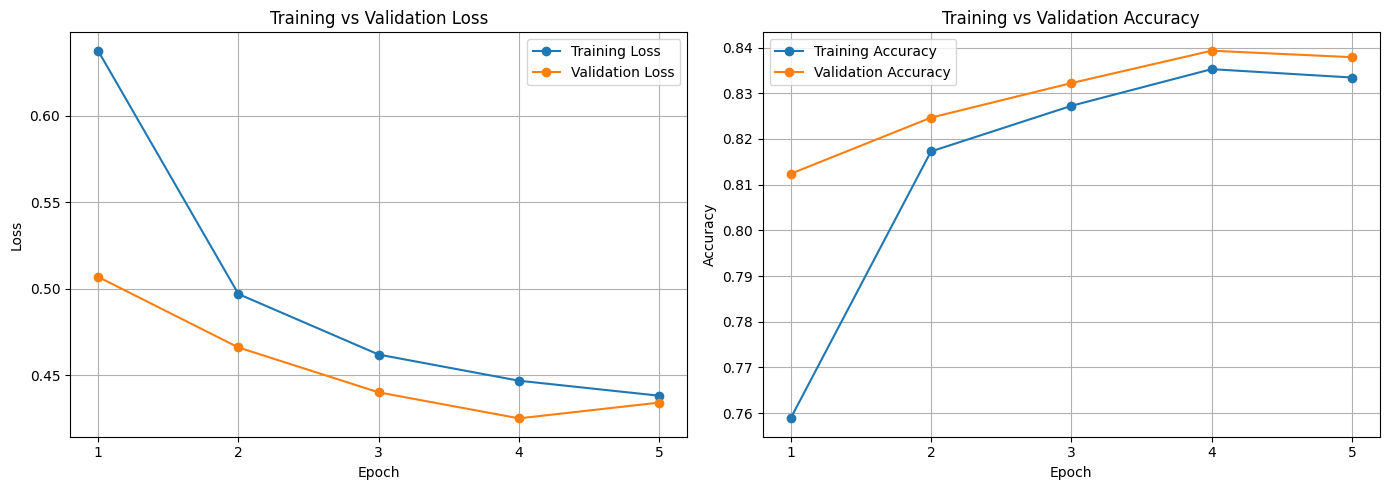

In [106]:
epochs = range(1, len(train_losses) + 1)

# Create two plots side by side
plt.figure(figsize=(14, 5))

# Plot 1: Training and validation loss
plt.subplot(1, 2, 1)

plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

# Plot 2: Training and validation accuracy
plt.subplot(1, 2, 2)

plt.plot(
    epochs,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [107]:
def evaluate_model(model, data_loader, device):

    # Put model in evaluation mode
    model.eval()

    # Lists to store evaluation results
    all_images = []
    all_labels = []
    all_predictions = []
    all_probabilities = []

    # Disable gradient calculations
    with torch.no_grad():

        for images, labels in data_loader:

            # Move images to GPU
            images = images.to(device)

            # Forward pass
            outputs = model(images)

            # Convert logits into probabilities
            probabilities = F.softmax(outputs, dim=1)

            # Get predicted classes
            predictions = outputs.argmax(dim=1)

            # Store original images on CPU
            all_images.extend(images.cpu())

            # Store actual labels
            all_labels.extend(labels.cpu().tolist())

            # Store predicted labels
            all_predictions.extend(predictions.cpu().tolist())

            # Store prediction probabilities
            all_probabilities.extend(probabilities.cpu().tolist())

    # Return all evaluation results
    return {
        "images": all_images,
        "labels": all_labels,
        "predictions": all_predictions,
        "probabilities": all_probabilities
    }

In [108]:
class_names = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral_Pneumonia"
]

In [109]:
baseline_results = evaluate_model(
    model=baseline_model,
    data_loader=val_loader,
    device=device
)



all_images_resnet = baseline_results["images"]
all_labels_resnet = baseline_results["labels"]
all_predictions_resnet = baseline_results["predictions"]
all_probabilities_resnet = baseline_results["probabilities"]

In [111]:
print(
    classification_report(
        all_labels_resnet,
        all_predictions_resnet,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)

                 precision    recall  f1-score   support

          COVID       0.76      0.82      0.79       361
   Lung_Opacity       0.79      0.82      0.81       601
         Normal       0.88      0.85      0.87      1019
Viral_Pneumonia       0.96      0.87      0.91       135

       accuracy                           0.84      2116
      macro avg       0.85      0.84      0.84      2116
   weighted avg       0.84      0.84      0.84      2116



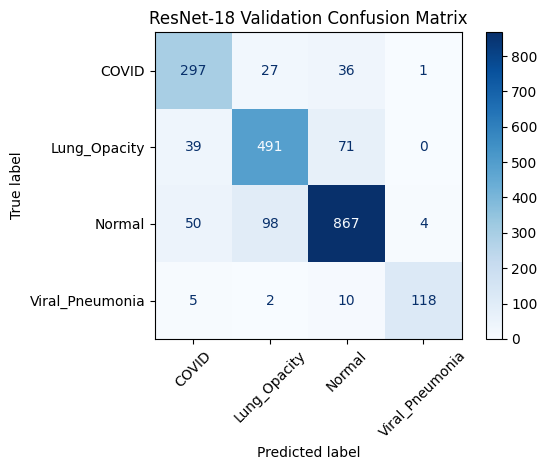

In [113]:

cm = confusion_matrix(
    all_labels_resnet,
    all_predictions_resnet,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.xticks(rotation=45)
plt.title("ResNet-18 Validation Confusion Matrix")
plt.tight_layout()
plt.show()

**Baseline Trained and Evaluated; Now, Train DesNet**

In [114]:
# load the pretrained DenseNet-121
densenet_model = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 247MB/s]


In [115]:
# freeze all pretrained parameters
for param in densenet_model.parameters():
    param.requires_grad = False

In [116]:
# replace the classifier
num_features = densenet_model.classifier.in_features

densenet_model.classifier = nn.Linear(num_features, 4)

In [117]:
# unfreeze the new layer
for param in densenet_model.classifier.parameters():
    param.requires_grad = True

In [118]:
# set model to device
densenet_model = densenet_model.to(device)

In [119]:
# setup loss and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    densenet_model.classifier.parameters(),
    lr=0.001
)

In [120]:
# train and evaluate the densenet model
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

num_epochs = 5

for epoch in range(num_epochs):
    train_loss, train_accuracy = train_one_epoch(
        densenet_model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate_one_epoch(
        densenet_model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch 1/5 | Train Loss: 0.6058 | Train Accuracy: 0.7720 | Val Loss: 0.4758 | Val Accuracy: 0.8289
Epoch 2/5 | Train Loss: 0.4614 | Train Accuracy: 0.8324 | Val Loss: 0.4316 | Val Accuracy: 0.8431
Epoch 3/5 | Train Loss: 0.4225 | Train Accuracy: 0.8434 | Val Loss: 0.4123 | Val Accuracy: 0.8549
Epoch 4/5 | Train Loss: 0.4065 | Train Accuracy: 0.8511 | Val Loss: 0.4315 | Val Accuracy: 0.8455
Epoch 5/5 | Train Loss: 0.3928 | Train Accuracy: 0.8574 | Val Loss: 0.3975 | Val Accuracy: 0.8568


In [123]:
densenet_results = evaluate_model(
    densenet_model,
    val_loader,
    device
)


all_images_densenet = densenet_results["images"]
all_labels_densenet = densenet_results["labels"]
all_predictions_densenet = densenet_results["predictions"]
all_probabilities_densenet = densenet_results["probabilities"]

In [124]:
print(classification_report(
    all_labels_densenet,
    all_predictions_densenet,
    target_names=[
        "COVID",
        "Lung_Opacity",
        "Normal",
        "Viral_Pneumonia"
    ]
))

                 precision    recall  f1-score   support

          COVID       0.91      0.74      0.81       361
   Lung_Opacity       0.84      0.81      0.82       601
         Normal       0.84      0.92      0.88      1019
Viral_Pneumonia       0.95      0.90      0.92       135

       accuracy                           0.86      2116
      macro avg       0.88      0.84      0.86      2116
   weighted avg       0.86      0.86      0.86      2116



In [125]:
cm_densenet = confusion_matrix(all_labels_densenet, all_predictions_densenet)
print(cm)

[[297  27  36   1]
 [ 39 491  71   0]
 [ 50  98 867   4]
 [  5   2  10 118]]


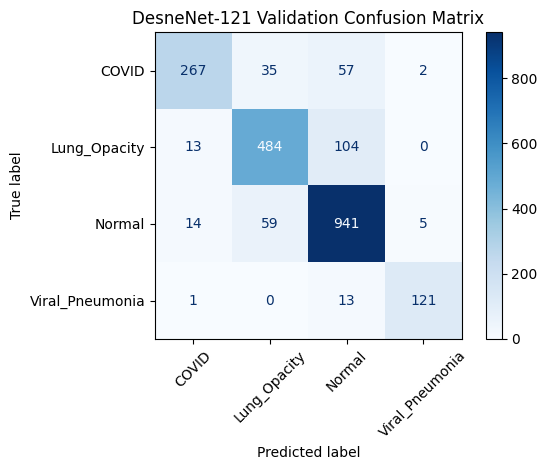

In [126]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_densenet,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.xticks(rotation=45)
plt.title("DesneNet-121 Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [72]:
# # Evaluate ResNet-18
# resnet_labels, resnet_predictions = evaluate_model(
#     baseline_model, val_loader, device
# )

# # Evaluate DenseNet-121
# densenet_labels, densenet_predictions = evaluate_model(
#     densenet_model, val_loader, device
# )

In [128]:

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score"
    ],
    "ResNet-18": [
        accuracy_score(all_labels_resnet, all_predictions_resnet),
        precision_score(all_labels_resnet, all_predictions_resnet, average="macro", zero_division=0),
        recall_score(all_labels_resnet, all_predictions_resnet, average="macro", zero_division=0),
        f1_score(all_labels_resnet, all_predictions_resnet, average="macro", zero_division=0)
    ],
    "DenseNet-121": [
        accuracy_score(all_labels_densenet, all_predictions_densenet),
        precision_score(all_labels_densenet, all_predictions_densenet, average="macro", zero_division=0),
        recall_score(all_labels_densenet, all_predictions_densenet, average="macro", zero_division=0),
        f1_score(all_labels_densenet, all_predictions_densenet, average="macro", zero_division=0)
    ]
})

comparison = comparison.set_index("Metric")
display(comparison.round(4))

,ResNet-18,DenseNet-121
Metric,,
Accuracy,0.8379,0.8568
Macro Precision,0.8486,0.8829
Macro Recall,0.8411,0.8412
Macro F1-score,0.8440,0.8593


**Overall Model Performance**

**ResNet-18** correctly classified **1,765** images and misclassified **351** images, giving an accuracy of **83.41%** and an error rate of **16.59%**.

**DenseNet-121** correctly classified **1,828** images and misclassified **288** images, achieving an accuracy of **86.39%** and an error rate of **13.61%.**

**DenseNet-121** therefore correctly classified **63** more images than ResNet-18 and achieved approximately **2.98** percentage points higher accuracy.

These results indicate that DenseNet-121 demonstrated better overall performance on the validation dataset.

**ERROR ANALYSIS**

In [129]:
# Convert labels and predictions into NumPy arrays
all_labels = np.array(baseline_results["labels"])
all_predictions = np.array(baseline_results["predictions"])

# Find the positions of incorrect predictions
misclassified_indices = np.where(
    all_labels != all_predictions
)[0]

print("Total validation images (ResNet-18):", len(all_labels))
print("Misclassified images (ResNet-18):", len(misclassified_indices))
print("Correct predictions (ResNet-18):", len(all_labels) - len(misclassified_indices))

Total validation images (ResNet-18): 2116
Misclassified images (ResNet-18): 343
Correct predictions (ResNet-18): 1773


In [130]:
# Convert labels and predictions into NumPy arrays
all_labels = np.array(densenet_results["labels"])
all_predictions = np.array(densenet_results["predictions"])

# Find the positions of incorrect predictions
misclassified_indices = np.where(
    all_labels != all_predictions
)[0]

print("Total validation images (Densenet-121):", len(all_labels))
print("Misclassified images (Densenet-121):", len(misclassified_indices))
print("Correct predictions (Densenet-121):", len(all_labels) - len(misclassified_indices))

Total validation images (Densenet-121): 2116
Misclassified images (Densenet-121): 303
Correct predictions (Densenet-121): 1813


In [131]:
# ResNet-18
resnet_labels = np.array(baseline_results["labels"])
resnet_predictions = np.array(baseline_results["predictions"])

resnet_errors = np.where(
    resnet_labels != resnet_predictions
)[0]


# DenseNet-121
densenet_labels = np.array(densenet_results["labels"])
densenet_predictions = np.array(densenet_results["predictions"])

densenet_errors = np.where(
    densenet_labels != densenet_predictions
)[0]

In [132]:
# check for common shared errors in two models
# Images misclassified by both models
common_errors = np.intersect1d(
    resnet_errors,
    densenet_errors
)

print(
    "Images misclassified by both models:",
    len(common_errors)
)

Images misclassified by both models: 187


In [133]:
# check for the error that is unique to both models
# Images misclassified only by ResNet-18
resnet_only_errors = np.setdiff1d(
    resnet_errors,
    densenet_errors
)

# Images misclassified only by DenseNet-121
densenet_only_errors = np.setdiff1d(
    densenet_errors,
    resnet_errors
)

print("Errors unique to ResNet-18:", len(resnet_only_errors))

print("Errors unique to DenseNet-121:", len(densenet_only_errors))

Errors unique to ResNet-18: 156
Errors unique to DenseNet-121: 116


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0836544..2.4831376].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.5005665].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..1.0888019].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.5528543].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.5528543].


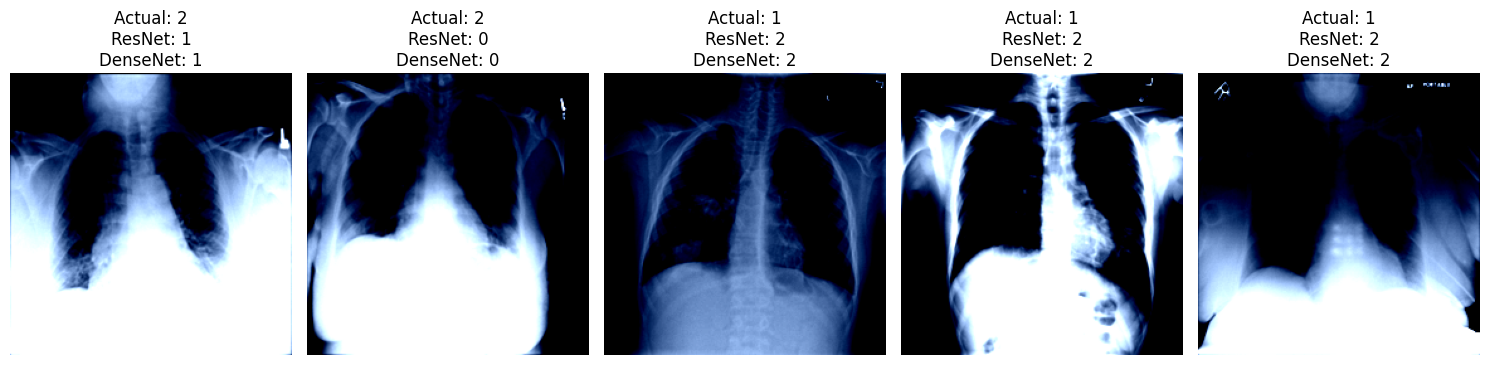

In [134]:
# visulaize the common errors in both models

# Select up to 5 images misclassified by both models
selected_errors = common_errors[:5]

plt.figure(figsize=(15, 5))

for i, idx in enumerate(selected_errors):

    image = baseline_results["images"][idx]

    actual_label = resnet_labels[idx]

    resnet_prediction = resnet_predictions[idx]

    densenet_prediction = densenet_predictions[idx]

    plt.subplot(1, 5, i + 1)

    plt.imshow(image.permute(1, 2, 0))

    plt.title(
        f"Actual: {actual_label}\n"
        f"ResNet: {resnet_prediction}\n"
        f"DenseNet: {densenet_prediction}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

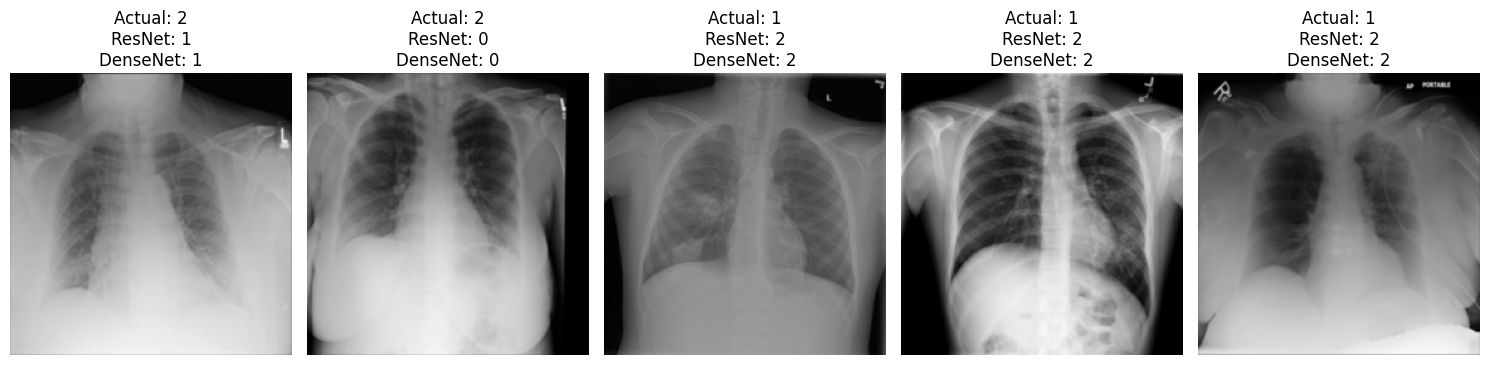

In [135]:
# VIEW THE UNNORMALIZED VERSIONS OF THE IMAGES

# Select five images misclassified by both models
selected_errors = common_errors[:5]

# Convert mean and std to tensors; the former cell above is the unnormalized version visualized
mean_tensor = torch.tensor(mean).view(3, 1, 1)
std_tensor = torch.tensor(std).view(3, 1, 1)

plt.figure(figsize=(15, 6))

for i, idx in enumerate(selected_errors):

    # Retrieve the image
    image = baseline_results["images"][idx]

    # Reverse normalisation
    image = image * std_tensor + mean_tensor

    # Keep pixel values between 0 and 1
    image = image.clamp(0, 1)

    # Retrieve labels and predictions
    actual_label = resnet_labels[idx]
    resnet_prediction = resnet_predictions[idx]
    densenet_prediction = densenet_predictions[idx]

    # Display image
    plt.subplot(1, 5, i + 1)

    plt.imshow(image.permute(1, 2, 0))

    plt.title(
        f"Actual: {actual_label}\n"
        f"ResNet: {resnet_prediction}\n"
        f"DenseNet: {densenet_prediction}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

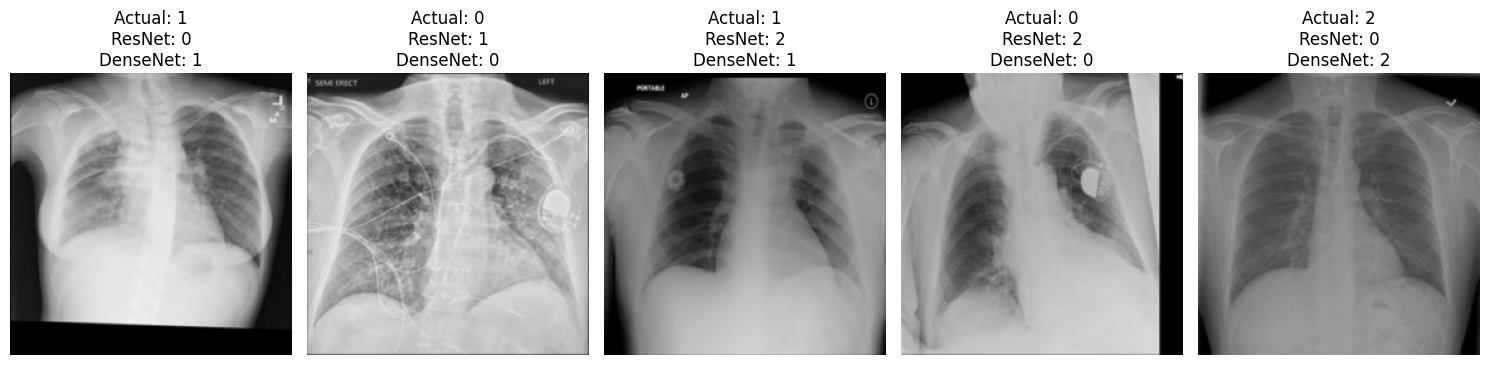

In [136]:
# RESNET-1'S UNIQUE ERRORS

# Select up to 5 errors unique to ResNet-18
selected_errors = resnet_only_errors[:5]

plt.figure(figsize=(15, 6))

for i, idx in enumerate(selected_errors):

    # Retrieve image
    image = baseline_results["images"][idx]

    # Reverse normalisation
    image = image * std_tensor + mean_tensor
    image = image.clamp(0, 1)

    # Retrieve actual and predicted labels
    actual_label = resnet_labels[idx]
    resnet_prediction = resnet_predictions[idx]
    densenet_prediction = densenet_predictions[idx]

    plt.subplot(1, 5, i + 1)

    plt.imshow(image.permute(1, 2, 0))

    plt.title(
        f"Actual: {actual_label}\n"
        f"ResNet: {resnet_prediction}\n"
        f"DenseNet: {densenet_prediction}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

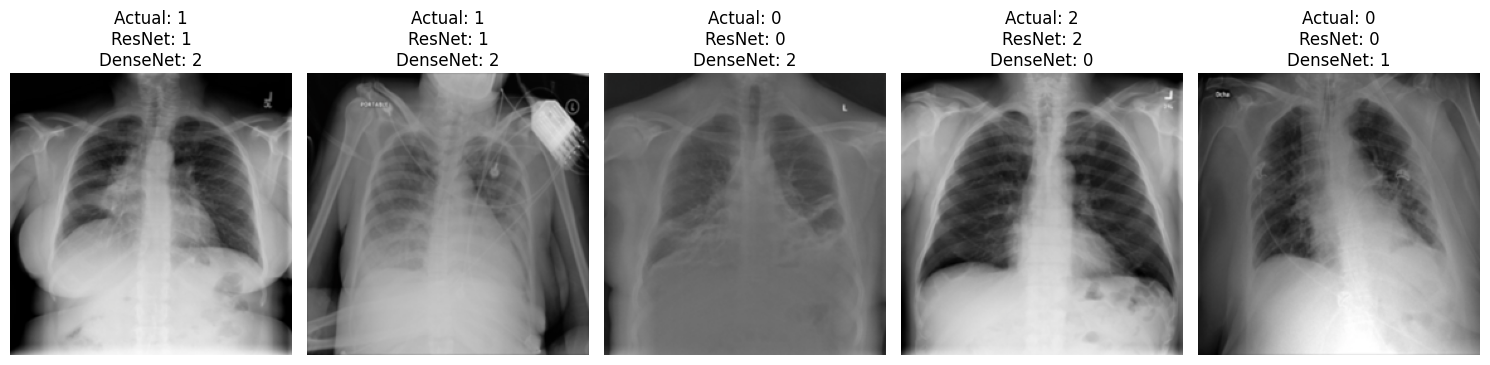

In [137]:
# DENSENET'S UNIQUE ERRORS

# Select up to 5 errors unique to DenseNet-121
selected_errors = densenet_only_errors[:5]

plt.figure(figsize=(15, 6))

for i, idx in enumerate(selected_errors):

    # Retrieve image
    image = baseline_results["images"][idx]

    # Reverse normalisation
    image = image * std_tensor + mean_tensor
    image = image.clamp(0, 1)

    # Retrieve actual and predicted labels
    actual_label = densenet_labels[idx]
    resnet_prediction = resnet_predictions[idx]
    densenet_prediction = densenet_predictions[idx]

    plt.subplot(1, 5, i + 1)

    plt.imshow(image.permute(1, 2, 0))

    plt.title(
        f"Actual: {actual_label}\n"
        f"ResNet: {resnet_prediction}\n"
        f"DenseNet: {densenet_prediction}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [138]:
# RESNET-18'S UNIQUE ERRORS

# ResNet-18
resnet_confusion = pd.crosstab(
    pd.Series(resnet_labels, name="Actual"),
    pd.Series(resnet_predictions, name="Predicted")
)

print("ResNet-18 Class Confusion:")
display(resnet_confusion)


# DenseNet-121
densenet_confusion = pd.crosstab(
    pd.Series(densenet_labels, name="Actual"),
    pd.Series(densenet_predictions, name="Predicted")
)

print("DenseNet-121 Class Confusion:")
display(densenet_confusion)

ResNet-18 Class Confusion:


Predicted,0,1,2,3
Actual,,,,
0,297,27,36,1
1,39,491,71,0
2,50,98,867,4
3,5,2,10,118


DenseNet-121 Class Confusion:


Predicted,0,1,2,3
Actual,,,,
0,267,35,57,2
1,13,484,104,0
2,14,59,941,5
3,1,0,13,121


The confusion matrices provided further insight into the classification behaviour of both models.

For ResNet-18, Class 2 had the highest recall (**93.92**%), followed by Class 3 (**91.85%**). Class 1 had the lowest recall (**66.89%**), indicating that it was the most challenging class for this model.

For DenseNet-121, Class 3 had the highest recall (**91.85%**), closely followed by Class 2 (**91.17%**). Class 1 also had the lowest recall (**78.87%**).

A comparison of the class-wise results showed that:

DenseNet-121 performed better on Class 0, with a recall of **83.38%** compared with **78.12%** for ResNet-18.

DenseNet-121 also performed better on Class 1, achieving **78.87%** recall compared with **66.89%** for ResNet-18.

ResNet-18 performed better on Class 2, achieving **93.92%** recall compared with **91.17%** for DenseNet-121.

Both models achieved the same recall of **91.85%** on Class 3.

A particularly noticeable pattern was the misclassification of Class 1 as Class 2. ResNet-18 made this error on **162** images, while DenseNet-**121** made it on **94** images.

Class 0 was also frequently misclassified as Class 2, with **66** errors for ResNet-18 and **34** for DenseNet-121.

However, DenseNet-121 made more errors when predicting Class 2 images as Class 1, with **50** such errors compared with **34** for ResNet-18.

These findings indicate that DenseNet-121 improved the distinction between certain classes, although some classification challenges remained.

In [139]:
# Convert probabilities to a NumPy array
resnet_probabilities = np.array(
    baseline_results["probabilities"]
)

# Get the highest predicted probability for each image
resnet_confidences = np.max(
    resnet_probabilities,
    axis=1
)

# Identify incorrect predictions
resnet_wrong = (
    resnet_labels != resnet_predictions
)

# Select incorrect predictions with confidence >= 90%
resnet_high_conf_errors = np.where(
    resnet_wrong & (resnet_confidences >= 0.90)
)[0]


print(
    "High-confidence incorrect predictions (ResNet-18):",
    len(resnet_high_conf_errors)
)

High-confidence incorrect predictions (ResNet-18): 29


The confidence analysis identified 49 high-confidence incorrect predictions from ResNet-18, using a confidence threshold of 90%.

These predictions represent approximately **13.96%** of all ResNet-18 misclassifications.

This finding is important because it demonstrates that a model can produce an incorrect prediction with a high level of confidence. Consequently, prediction confidence should not be interpreted as a guarantee of classification correctness.

Further analysis of DenseNet-121's prediction probabilities would be necessary to determine whether it exhibits a similar pattern.

Consider the **Grad-CAM (Gradient Weighted Class Activation Mapping)** for further analyses of the behaviours of the models

In [140]:
print(test_loader)

In [141]:
# Evaluate ResNet-18 on the test dataset
resnet_test_results = evaluate_model(
    baseline_model,
    test_loader,
    device
)

# Evaluate DenseNet-121 on the test dataset
densenet_test_results = evaluate_model(
    densenet_model,
    test_loader,
    device
)

print("Both models have been evaluated on the test dataset.")

Both models have been evaluated on the test dataset.


In [142]:
def calculate_metrics(results):

    labels = np.array(results["labels"])
    predictions = np.array(results["predictions"])

    return {
        "Accuracy": accuracy_score(labels, predictions),
        "Precision": precision_score(
            labels, predictions, average="macro"
        ),
        "Recall": recall_score(
            labels, predictions, average="macro"
        ),
        "F1 Score": f1_score(
            labels, predictions, average="macro"
        )
    }


# Calculate metrics for both models
resnet_test_metrics = calculate_metrics(
    resnet_test_results
)

densenet_test_metrics = calculate_metrics(
    densenet_test_results
)

In [143]:

test_comparison = pd.DataFrame({
    "ResNet-18": resnet_test_metrics,
    "DenseNet-121": densenet_test_metrics
})

display(test_comparison.round(4))

,ResNet-18,DenseNet-121
Accuracy,0.8517,0.8564
Precision,0.8559,0.8808
Recall,0.8420,0.8330
F1 Score,0.8470,0.8538


In [144]:
# ResNet-18
print("RESNET-18 TEST CLASSIFICATION REPORT")

print(
    classification_report(
        resnet_test_results["labels"],
        resnet_test_results["predictions"],
        digits=4
    )
)


# DenseNet-121
print("DENSENET-121 TEST CLASSIFICATION REPORT")

print(
    classification_report(
        densenet_test_results["labels"],
        densenet_test_results["predictions"],
        digits=4
    )
)

RESNET-18 TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.7567    0.8591    0.8047       362
           1     0.8202    0.8106    0.8154       602
           2     0.8985    0.8773    0.8878      1019
           3     0.9483    0.8209    0.8800       134

    accuracy                         0.8517      2117
   macro avg     0.8559    0.8420    0.8470      2117
weighted avg     0.8551    0.8517    0.8525      2117

DENSENET-121 TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.8915    0.7265    0.8006       362
           1     0.8302    0.8123    0.8212       602
           2     0.8506    0.9274    0.8873      1019
           3     0.9508    0.8657    0.9062       134

    accuracy                         0.8564      2117
   macro avg     0.8808    0.8330    0.8538      2117
weighted avg     0.8581    0.8564    0.8549      2117



In [145]:

# Save the trained model and its configuration
torch.save({
    "model_state_dict": densenet_model.state_dict(),
    "num_classes": 4,
    "image_size": 224,
    "class_names": [
        "COVID",
        "Lung_Opacity",
        "Normal",
        "Viral_Pneumonia"
    ],
    "mean": [0.485, 0.456, 0.406],
    "std": [0.229, 0.224, 0.225]
}, "densenet121_chest_xray.pth")

In [157]:

checkpoint_path = "densenet121_chest_xray.pth"

if os.path.exists(checkpoint_path):
    print("Model checkpoint saved successfully!")
    print(f"File size: {os.path.getsize(checkpoint_path) / (1024 * 1024):.2f} MB")
else:
    print("Checkpoint file not found.")

Model checkpoint saved successfully!
File size: 27.13 MB


**Reconstruct the Densenet-121 Architecture**

In [147]:
loaded_model = models.densenet121(weights=None)

# replace the final classification layer
loaded_model.classifier = nn.Linear(
    loaded_model.classifier.in_features, 4
)

print(loaded_model)

DenseNet(
  (features): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (denseblock1): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu

In [150]:
# Load the sabed checkpoint

checkpoint = torch.load(
    "densenet121_chest_xray.pth",
    map_location=device,
    weights_only=True
)


# load the trained weights into the recreated architecture
loaded_model.load_state_dict(checkpoint["model_state_dict"])

# move the model to the appropriate device
loaded_model = loaded_model.to(device)

# set up the model to evaluation mode
loaded_model.eval()

print("DenseNet-121 model loaded successfully!")

DenseNet-121 model loaded successfully!


In [151]:
inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean,
        std=std
    )
])



# class names (verify again that order is consistent)

class_names = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral_Pneumonia"
]

In [155]:
def predict_image(image_path):

    # open the image
    image = Image.open(image_path).convert("RGB")

    # Apply the same preprocessing used during training
    image_tensor = inference_transform(image)

    # add a batch dimension
    image_tensor = image_tensor.unsqueeze(0).to(device)

    # make prediction
    with torch.no_grad():
        outputs = loaded_model(image_tensor)

        probabilities = F.softmax(outputs, dim=1)

        confidence, predicted_class = torch.max(
            probabilities, dim=1
        )

        # get predicted class name
        predicted_label = class_names[predicted_class.item()]

    return {
        "predicted_class": predicted_label,
        "confidence": confidence.item(),
        "probabilities": probabilities.cpu().numpy()[0]
        }

In [158]:
test_df.head()

,path,label,le_label
15672,/kaggle/input/datasets/tawsifurrahman/covid19-...,Normal,2
8624,/kaggle/input/datasets/tawsifurrahman/covid19-...,Lung_Opacity,1
19211,/kaggle/input/datasets/tawsifurrahman/covid19-...,Normal,2
3623,/kaggle/input/datasets/tawsifurrahman/covid19-...,Lung_Opacity,1
17735,/kaggle/input/datasets/tawsifurrahman/covid19-...,Normal,2


**TEST INFERENCE FUNCTION ON ONE IMAGE**

In [163]:
sample_image_path = test_df.iloc[0]["path"]

# pass the image to our prediction function
result = predict_image(sample_image_path)

# display the results
print("Predicted class:", result["predicted_class"])
print("Confidence:", f'{result["confidence"]:.4f}')

print("\nClass probabilities:")


for class_name, probability in zip(
    class_names,
    result["probabilities"]
):
    print(f"{class_name}: {probability:.4f}")

print("\nMore Information:")
# Get the actual numeric label
actual_label = test_df.iloc[0]["label"]

# Get the predicted class
predicted_label = result["predicted_class"]

print("Actual numeric label:", actual_label)
print("Predicted class:", predicted_label)

Predicted class: Normal
Confidence: 0.7994

Class probabilities:
COVID: 0.0036
Lung_Opacity: 0.1970
Normal: 0.7994
Viral_Pneumonia: 0.0000

More Information:
Actual numeric label: Normal
Predicted class: Normal


**TEST INFERENCE FUNCTION ON MULTIPLE IMAGES**

In [166]:
for i in range(5):
    image_path = test_df.iloc[i]["path"]

    result = predict_image(image_path)

    actual_label = test_df.iloc[i]["label"]

    predicted_label = result["predicted_class"]

    print(f"\nImage {i + 1}")
    print("Actual class:", actual_label)
    print("Predicted class:", predicted_label)
    print("Confidence:", f"{result["confidence"]:.4f}")
    print("Correct:", actual_label == predicted_label)


Image 1
Actual class: Normal
Predicted class: Normal
Confidence: 0.7994
Correct: True

Image 2
Actual class: Lung_Opacity
Predicted class: Normal
Confidence: 0.8360
Correct: False

Image 3
Actual class: Normal
Predicted class: Normal
Confidence: 0.9921
Correct: True

Image 4
Actual class: Lung_Opacity
Predicted class: Lung_Opacity
Confidence: 0.8490
Correct: True

Image 5
Actual class: Normal
Predicted class: Normal
Confidence: 0.9497
Correct: True


In [168]:
# check if the function can handle errors gracefully

try:
    result = predict_image("nonexistent_image.jpg")

except Exception as e:
    print("Error encountered:", e)

Error encountered: [Errno 2] No such file or directory: 'nonexistent_image.jpg'
